In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [2]:
# Load Data
music_data = pd.read_csv("spotify_streaming_alia.csv")  # Replace with actual filename
weather_data = pd.read_csv("vancouverWeather.csv")  # Replace with actual filename

In [3]:
music_data['genre'] = music_data['genre'].astype(str).str.strip().str.lower()

In [4]:
genre_mapping = {
    "lo-fi": ["lo-fi", "lo-fi beats", "lofi", "lo fi", "chillout"],
    "pop": ["pop", "soft pop", "bedroom pop", "synthpop", "pop rock", "indie pop", "norwegian pop", "pop urbaine", "dream pop", "hyperpop", "baroque pop", "chamber pop", "art pop"],
    "rock": ["rock", "classic rock", "modern rock", "progressive rock", "stoner rock", "rock and roll", "alternative rock", "gothic rock", "art rock"],
    "hip hop": ["hip-hop", "rap", "trap", "gangster rap", "hindi hip hop", "k-rap"],
    "indie": ["indie", "indie rock", "indie pop", "indie folk"],
    "classical": ["classical", "classical piano", "contemporary classical", "neoclassical", "chamber music", "orchestra", "composer", "opera", "choral", "requiem"],
    "jazz": ["jazz", "blues", "soul"],
    "electronic": ["electronic", "electronica", "downtempo", "ambient", "dark ambient", "trip hop"],
    "soundtrack": ["soundtrack", "musicals", "disney", "veronica mars"],
    "folk": ["folk", "folk rock", "anti-folk"],
    "korean": ["k-pop", "k-ballad", "korean"],
    "japanese": ["j-pop", "japanese", "japanese classical", "j-rock", "vocaloid"],
    "other": ["seen live", "anime", "female vocalists", "canada", "lebanon", "germany", "american", "5 seconds of summer", "booba", "dangdut", "variété française", "french pop", "chanson", "medieval", "new wave", "christmas", "dark cabaret", "opm", "lullaby"]
}

In [5]:
# Reverse mapping for lookup
reverse_map = {}
for key, group in genre_mapping.items():
    for g in group:
        reverse_map[g] = key

In [6]:
music_data['genre'] = music_data['genre'].map(reverse_map).fillna(music_data['genre'])

In [7]:
print(music_data['genre'].unique())

['indie' 'other' 'rock' 'rnb' 'pop' 'psychedelic pop' 'soundtrack'
 'country' 'hip hop' 'korean' 'jazz' 'britpop' 'folk' 'electronic' 'lo-fi'
 'instrumental' 'classical' 'piano' 'nan' 'spanish' 'japanese'
 'alternative r&b' 'alternative' 'post-punk' 'doo-wop']


In [8]:
# Convert timestamps to datetime format
music_data['timestamp'] = pd.to_datetime(music_data['endTime'])
weather_data['timestamp'] = pd.to_datetime(weather_data['datetime'])

In [9]:
# Round timestamps to nearest hour for merging
music_data['timestamp'] = music_data['timestamp'].dt.round('h')
weather_data['timestamp'] = weather_data['timestamp'].dt.round('h')

In [10]:
# Merge Data on Timestamp
merged_data = pd.merge(music_data, weather_data, on='timestamp', how='inner')

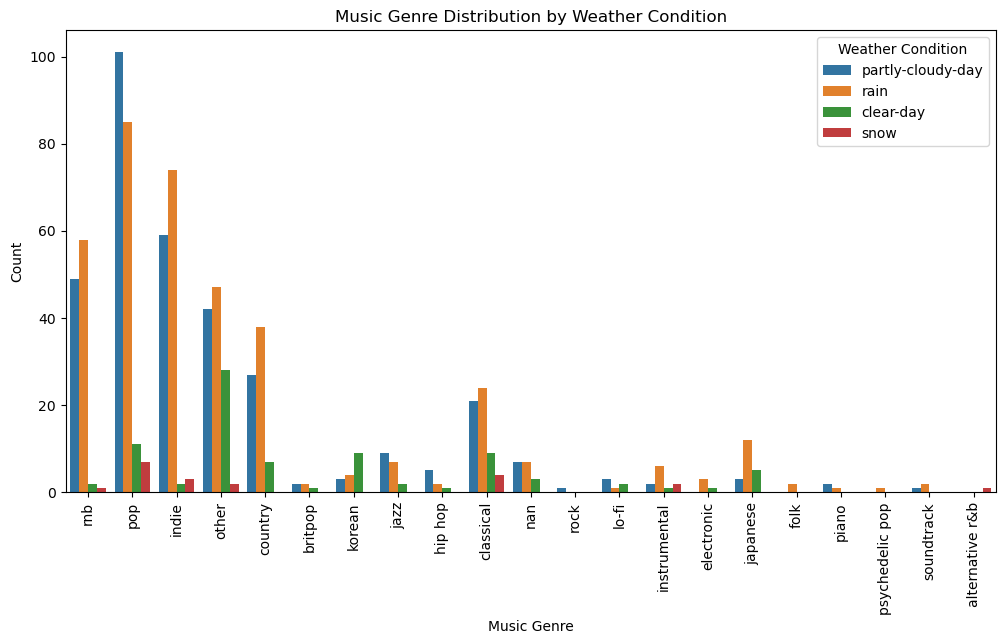

In [11]:
# Histogram: Genre Distribution by Weather Condition
plt.figure(figsize=(12, 6))
sns.countplot(data=merged_data, x='genre', hue='icon')
plt.title("Music Genre Distribution by Weather Condition")
plt.xticks(rotation=90)
plt.xlabel("Music Genre")
plt.ylabel("Count")
plt.legend(title="Weather Condition")
plt.show()

In [12]:
contingency_table = pd.crosstab(merged_data['icon'], merged_data['genre'])
chi2, p, dof, expected = stats.chi2_contingency(contingency_table)

print(f"Chi-Square Test Statistic: {chi2:.3f}")
print(p)

if p < 0.05:
    print("There is a significant relationship between Weather Condition and Music Genre.")
else:
    print("No significant relationship found between Weather Condition and Music Genre.")

Chi-Square Test Statistic: 182.056
3.1628062226885057e-14
There is a significant relationship between Weather Condition and Music Genre.


In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

In [14]:
df = merged_data[['icon', 'genre']].dropna()

In [15]:
icon_encoder = LabelEncoder()
genre_encoder = LabelEncoder()

In [16]:
df['icon_encoded'] = icon_encoder.fit_transform(df['icon'])
df['genre_encoded'] = genre_encoder.fit_transform(df['genre'])

In [17]:
X = df[['icon_encoded']]
y = df['genre_encoded']

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [19]:
dt_model = DecisionTreeClassifier()
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

In [20]:
print("Decision Tree Accuracy:", accuracy_score(y_test, dt_pred))

Decision Tree Accuracy: 0.24390243902439024


In [21]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [22]:
print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))

Random Forest Accuracy: 0.24390243902439024


In [23]:
knn_model = KNeighborsClassifier(n_neighbors=3)
knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)

In [24]:
print("KNN Accuracy:", accuracy_score(y_test, knn_pred))

KNN Accuracy: 0.16463414634146342


In [25]:
def recommend_genre_from_icon(current_icon):
    icon_code = icon_encoder.transform([current_icon])
    genre_code = model.predict([[icon_code[0]]])[0]
    genre = genre_encoder.inverse_transform([genre_code])[0]
    return genre